In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("First five rows of the Iris dataset:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)
df.info()


First five rows of the Iris dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


###KMeans Clustering

In [2]:

# KMeans Clustering

# Apply KMeans with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and predict cluster labels
kmeans_labels = kmeans.fit_predict(df)

# Add cluster labels to a copy of the dataset
kmeans_df = df.copy()
kmeans_df["Cluster"] = kmeans_labels

display(kmeans_df.head())

print("Number of data points in each cluster:")
print(kmeans_df["Cluster"].value_counts().sort_index())

# Display inertia
print("KMeans Inertia:", kmeans.inertia_)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


Number of data points in each cluster:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64
KMeans Inertia: 78.851441426146


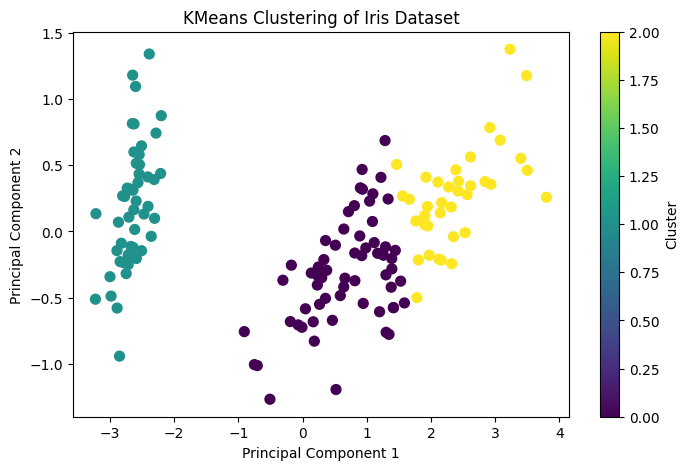

In [3]:

# Reduce the four features to two dimensions for visualization
pca = PCA(n_components=2)
iris_pca = pca.fit_transform(df)

# Plot KMeans clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    iris_pca[:, 0],
    iris_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.title("KMeans Clustering of Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()


### KMeans Clustering

**Description:** KMeans is an unsupervised clustering algorithm that partitions data into a predefined number of clusters. It assigns each data point to the nearest centroid and iteratively updates the centroids to minimize the within-cluster sum of squared distances.

**Suitability:** KMeans is suitable for the Iris dataset because it contains numerical features describing flower measurements. The algorithm groups flowers with similar measurements into clusters. Three clusters were selected to explore the natural grouping of the dataset.

**Visualization:** PCA was used to reduce the four-dimensional feature space to two dimensions for visualization. The scatter plot displays the clusters identified by KMeans.

**Observation:** The plot helps identify how the data points are grouped and whether the clusters overlap. Since the species labels were excluded, the clusters represent groups discovered from the numerical features rather than known flower species.


###Hierarchical Clustering

In [4]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(df)

hierarchical_df = df.copy()
hierarchical_df["Cluster"] = hierarchical_labels

print(hierarchical_df.head())
print(hierarchical_df["Cluster"].value_counts().sort_index())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
Cluster
0    64
1    50
2    36
Name: count, dtype: int64


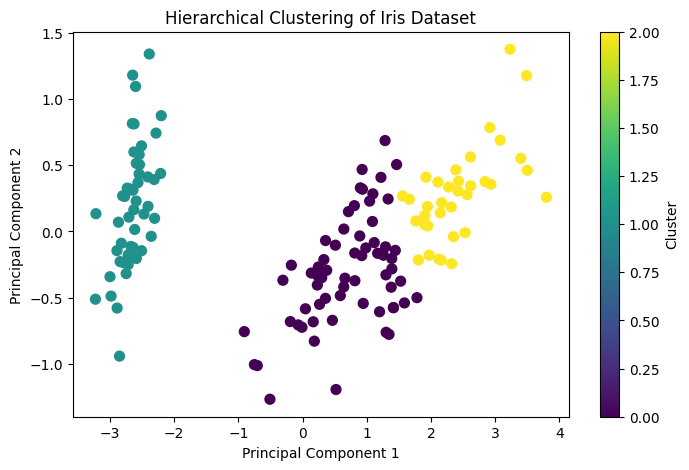

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    iris_pca[:, 0],
    iris_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering of Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

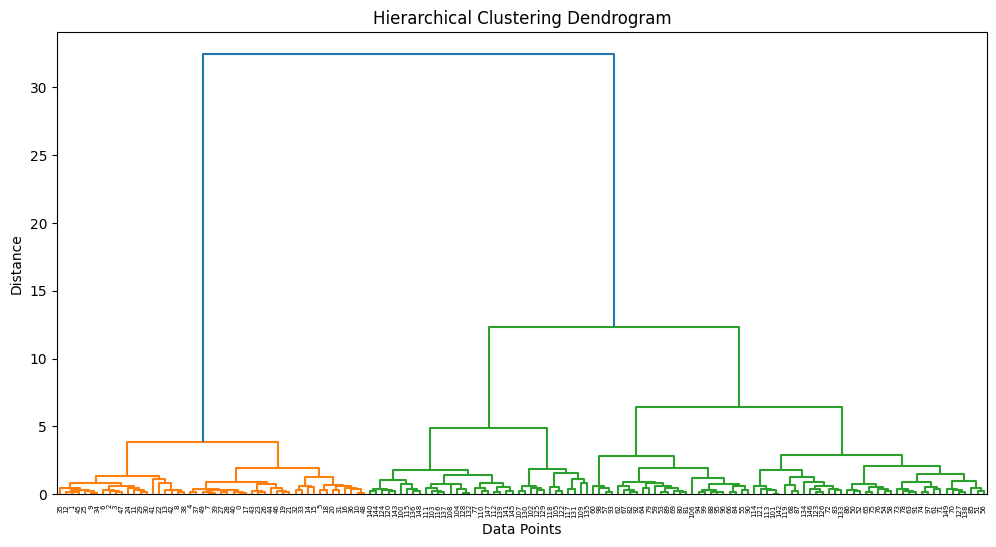

In [6]:
plt.figure(figsize=(12, 6))

Z = linkage(df, method="ward")
dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

### Hierarchical Clustering

**Description:** Hierarchical clustering is an unsupervised learning algorithm that groups data points into a hierarchy of clusters. Agglomerative clustering starts with each data point as an individual cluster and repeatedly merges the closest clusters.

**Suitability:** It is suitable for the Iris dataset because it groups flowers based on similarities in their numerical measurements. It also provides a hierarchical structure that can be visualized using a dendrogram.

**Observation:** The scatter plot shows the three clusters identified by hierarchical clustering after PCA dimensionality reduction. The dendrogram illustrates how individual data points and clusters merge at different distances.

## Conclusion

In this assignment, KMeans and Hierarchical Clustering were applied to the Iris dataset using its four numerical features.

KMeans grouped the data into three clusters by assigning data points to their nearest centroids. Hierarchical Clustering grouped similar data points through repeated merging, and the dendrogram illustrated the hierarchical relationships between the clusters.

PCA was used to reduce the four-dimensional dataset to two dimensions for visualizing both clustering results.

Both algorithms demonstrated how unsupervised learning can identify patterns and group similar data points without using species labels.